# MD-A\*: нативный перенос и сравнение

Ветка `research/md-astar`, исходный репозиторий `Incremental-MeshA/introduction`, база `cc58898`.

[Статья и оценка качества](docs/md_astar/report.md) · [PDF](docs/md_astar/report.pdf) · [Доказательство](docs/md_astar/method.md) · [Код](mesha/deferred.py).

Здесь используются только новые Python-измерения на исходном `car16`. Старые C++-артефакты сохранены отдельно и в ускорения не входят.

In [1]:
from pathlib import Path
import json, hashlib
from IPython.display import display, Markdown, Image
ROOT=Path.cwd()
a=json.loads((ROOT/'results/md_astar/analysis.json').read_text())
assert a['status']=='passed'
for path,sha in a['environment']['sha256'].items():
    assert hashlib.sha256((ROOT/path).read_bytes()).hexdigest()==sha,path
print({k:a[k] for k in ['cases','snapshot_records','runs','query_calls']})
print({k:a['environment'][k] for k in ['python','numpy','cpu','workers']})

{'cases': 40, 'snapshot_records': 280, 'runs': 1032, 'query_calls': 7656}
{'python': '3.12.14', 'numpy': '2.3.5', 'cpu': 'AMD EPYC 9V74 80-Core Processor', 'workers': 1}


## Прямое сравнение с общим ядром

Отношение времени MPGAA\* к MD-A\*: больше единицы означает выигрыш оболочки. Сначала суммируются перепланирования эпизода, затем берутся медиана трёх повторений и медиана парных отношений. Это не отношение двух несвязанных средних и не сравнение с историческими секундами.

In [2]:
rows=['| Набор | Ускорение | Выигрыши | Весь эпизод |','|---|---:|---:|---:|']
for co in ['original','mixed','validation','diagnostic']:
    x=a['comparisons'][co+':mpgaa']['online_s'];y=a['comparisons'][co+':mpgaa']['episode_s']
    rows.append(f'| {co} | {x["median"]:.3f} | {x["wins"]}/{x["n"]} | {y["median"]:.3f} |')
display(Markdown('\n'.join(rows)))

| Набор | Ускорение | Выигрыши | Весь эпизод |
|---|---:|---:|---:|
| original | 0.982 | 10/24 | 0.993 |
| mixed | 1.016 | 5/8 | 1.006 |
| validation | 1.004 | 2/4 | 1.035 |
| diagnostic | 144.077 | 4/4 | 12.381 |

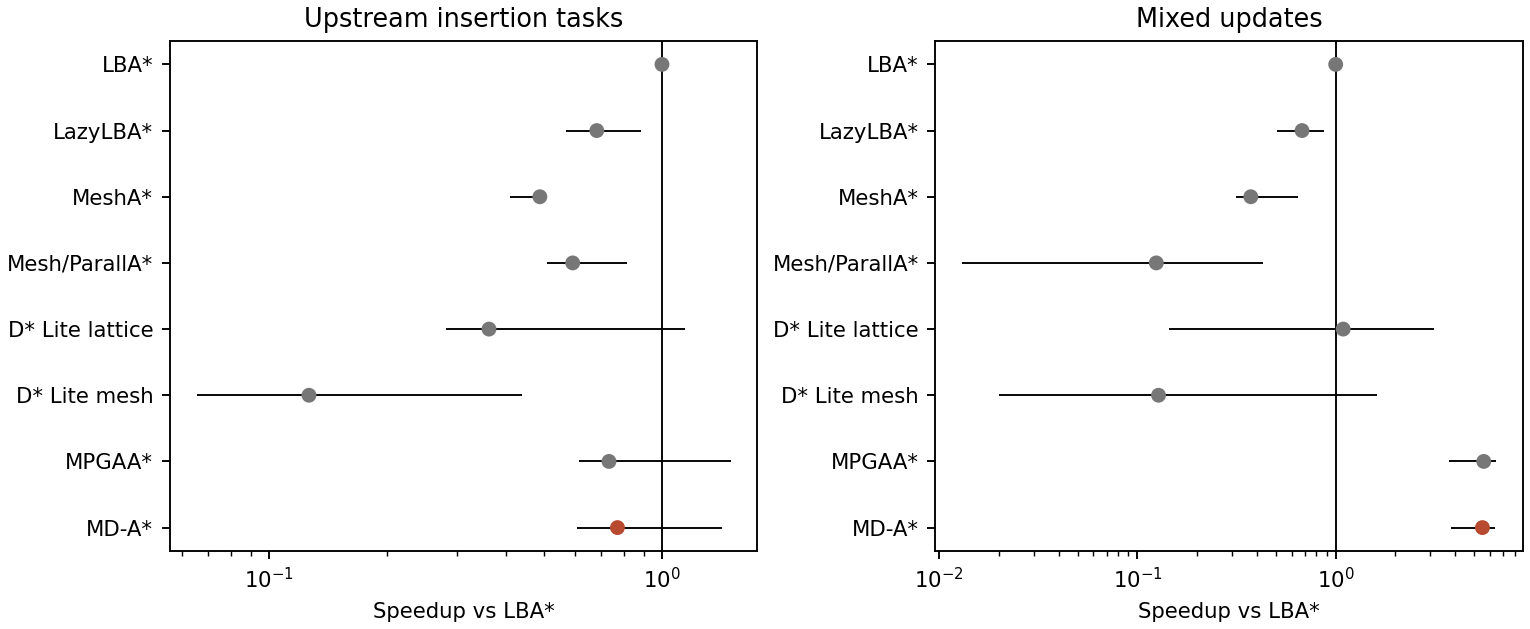

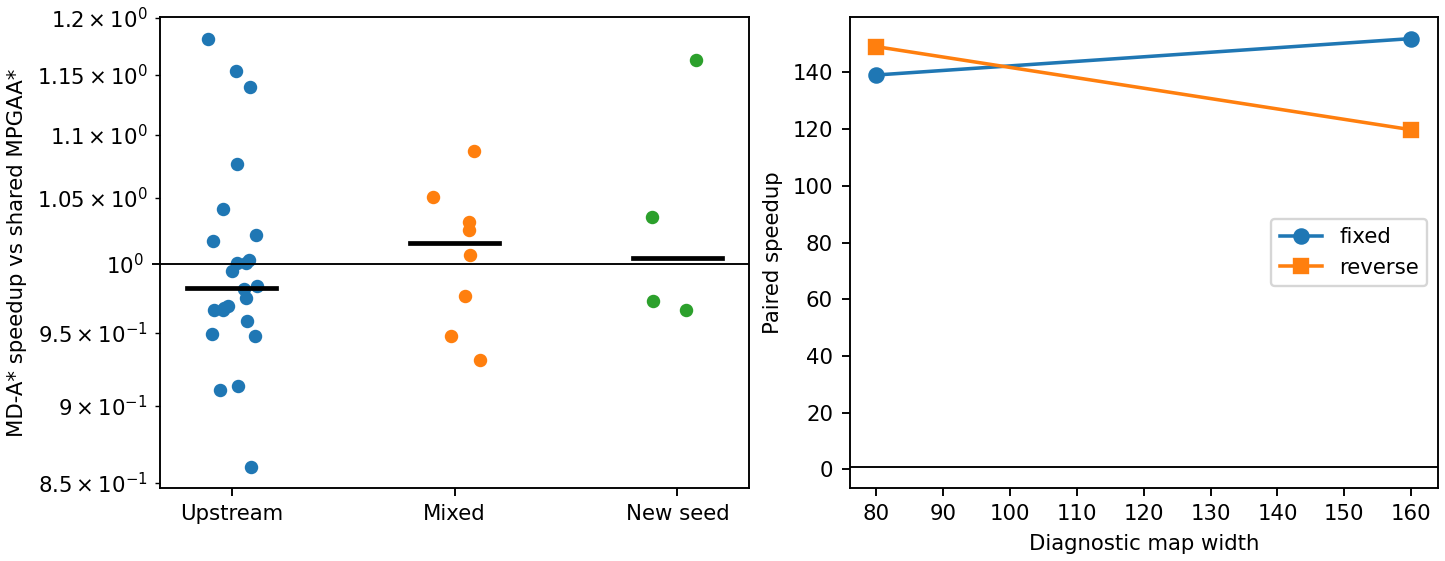

In [3]:
display(Image(filename=str(ROOT/'docs/md_astar/figures/comparison.png')))
display(Image(filename=str(ROOT/'docs/md_astar/figures/transfer.png')))

## Механизм и абляции

`md64` меняет силу клеточной оценки, `md_scan` — только просмотр отложенных клеток. Базовый MPGAA\* общий. Приближённый Mesh/ParallA\* оценивается вместе со стоимостью пути; его скорость не является преимуществом точного поиска.

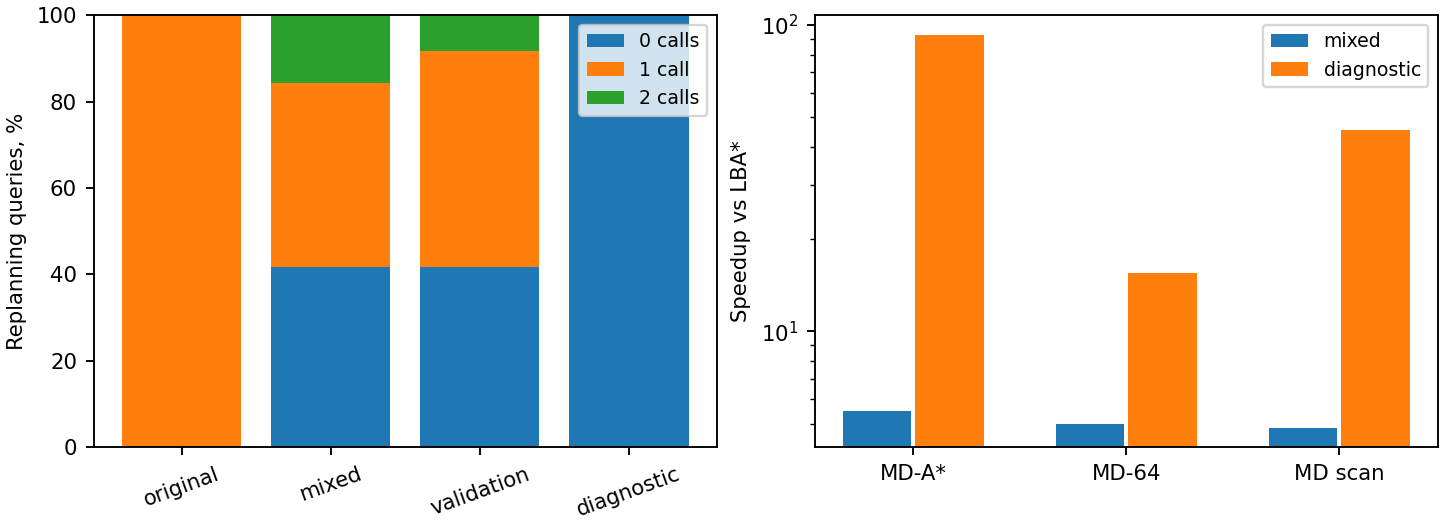

original Mesh/Parall max cost/optimum: 2.35960278492261 nonoptimal query records: 48
mixed Mesh/Parall max cost/optimum: 1.4118035723901987 nonoptimal query records: 61
validation Mesh/Parall max cost/optimum: 1.0570766239711769 nonoptimal query records: 52
diagnostic Mesh/Parall max cost/optimum: 1.0 nonoptimal query records: 0


In [4]:
display(Image(filename=str(ROOT/'docs/md_astar/figures/mechanism.png')))
for co in ['original','mixed','validation','diagnostic']:
    m=a['cohorts'][co]['methods']['mesh_parall']
    print(co,'Mesh/Parall max cost/optimum:',m['max_suboptimality_global'],'nonoptimal query records:',m['nonoptimal_queries'])

## Проверка корректности и качество работы

Независимый Dijkstra не использует эвристику или классы графов планировщиков. Отдельная проверка охватывает все 561 исходных запроса. Проверены покрытые клетки, курсы и стоимость примитивов, разрез/открытие карты, возвраты старта и реактивация старого освобождения. Математическая теорема относится к идеальной арифметике; float-реализация проверяется с допуском `1e-6`.

In [5]:
for name in ['verification.json','full_verification.json']:
    x=json.loads((ROOT/'results/md_astar'/name).read_text());assert x['status']=='passed'
    print(name,{k:v for k,v in x.items() if k in ['status','oracle_snapshots','instances','queries','comparisons','path_validations']})
print('Compiler milliseconds:',1000*a['environment']['certificate_compile_s'])

verification.json {'status': 'passed', 'oracle_snapshots': 308, 'comparisons': 1458}
full_verification.json {'status': 'passed', 'instances': 187, 'queries': 561, 'comparisons': 1122, 'path_validations': 1122}
Compiler milliseconds: 8.248755999829882


Сильные стороны: нативная интеграция, отдельный причинный контроль, зафиксированные данные, последовательные повторения, независимые проверки. Ограничения: четыре карты, один основной набор примитивов, небольшой временной поднабор, фиксированная цель, 2D-проверки коллизий, не подтверждённый внешний приоритет. Исходные задачи специально ломают путь и не содержат освобождений: диагностический выигрыш нельзя переносить на эту постановку.

Для нового измерения нужно сохранить старые `raw.jsonl`, `environment.json`, `completion_*.json` под другими именами и выполнить команды из [README](docs/md_astar/README.md). Этот ноутбук читает зафиксированные данные, а не запускает поиск заново.